['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'nothing', 'space']


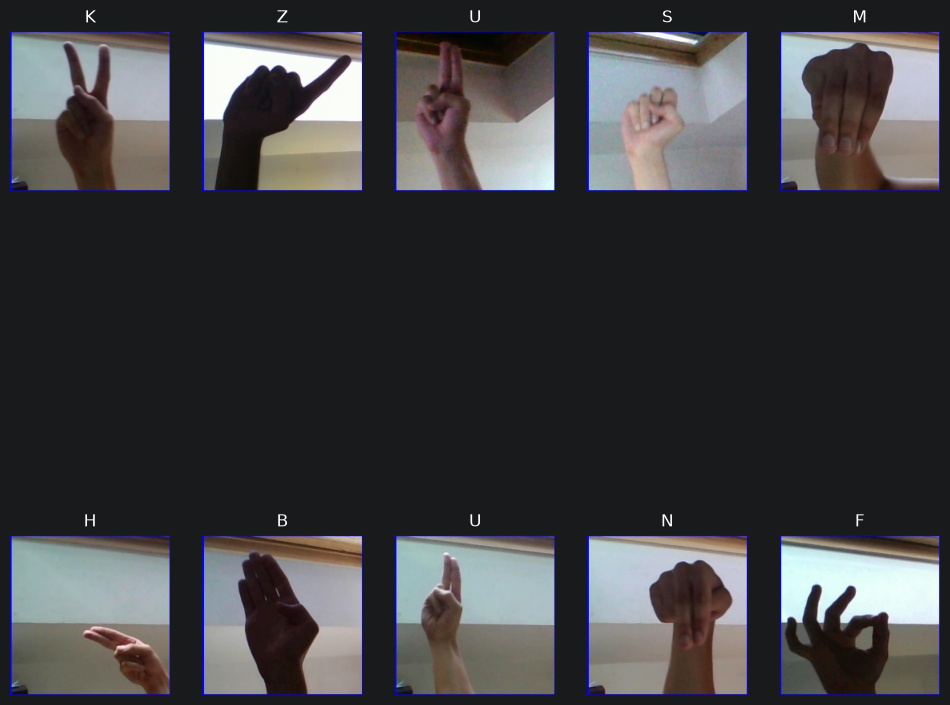

['A',
 'B',
 'C',
 'D',
 'E',
 'F',
 'G',
 'H',
 'I',
 'K',
 'L',
 'M',
 'N',
 'O',
 'P',
 'Q',
 'R',
 'S',
 'T',
 'U',
 'V',
 'W',
 'X',
 'Y']

['A',
 'B',
 'C',
 'D',
 'E',
 'F',
 'G',
 'H',
 'I',
 'K',
 'L',
 'M',
 'N',
 'O',
 'P',
 'Q',
 'R',
 'S',
 'T',
 'U',
 'V',
 'W',
 'X',
 'Y']

['A',
 'B',
 'C',
 'D',
 'E',
 'F',
 'G',
 'H',
 'I',
 'K',
 'L',
 'M',
 'N',
 'O',
 'P',
 'Q',
 'R',
 'S',
 'T',
 'U',
 'V',
 'W',
 'X',
 'Y']

57600 14400 24


In [8]:
from pathlib import Path
import torch
from torchvision import datasets, transforms
from PIL import Image
from torch.utils.data import Dataset, DataLoader, Subset
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

DATA_DIR = Path("..") / "data"
TRAIN_DIR = DATA_DIR / "asl_alphabet_train"/ "asl_alphabet_train"
TEST_DIR = DATA_DIR / "asl_alphabet_test"/ "asl_alphabet_test"

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3,[0.5]*3)
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3,[0.5]*3)
])

train_full = datasets.ImageFolder(TRAIN_DIR, transform=train_transform)
valid_full = datasets.ImageFolder(TRAIN_DIR, transform=eval_transform)
print(train_full.classes)

indices = list(range(len(train_full)))
train_idx, valid_idx = train_test_split(indices, test_size=0.2, random_state=42, stratify=train_full.targets)

train_set = Subset(train_full, train_idx)
valid_set = Subset(valid_full, valid_idx)

raw = datasets.ImageFolder(TRAIN_DIR)
fig, axes = plt.subplots(2,5, figsize=(12,12))

for ax, idx in zip(axes.flat, torch.randint(len(raw), (10,)).tolist()):
    img, label = raw[idx]
    ax.imshow(img); ax.set_title(raw.classes[label]); ax.axis("off")
plt.show()



class ASLTestDataset(Dataset):
    def __init__(self, root, class_to_index, transform=None):
        self.files = sorted(Path(root).glob("*jpg"))
        self.class_to_index = class_to_index
        self.transform = transform
        self.targets = [class_to_index[p.stem.split("_")[0]] for p in self.files]

    def __len__(self):
        return len(self.files)

    def __getitem__(self, index):
        path = self.files[index]
        label = self.class_to_index[path.stem.split("_")[0]]
        img = Image.open(path).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, label

test_ds = ASLTestDataset(TEST_DIR, train_full.class_to_idx, transform=eval_transform)

keep_classes = [c for c in train_full.classes if len(c) == 1 and c not in ("J", "Z")]

def get_targets(dataset):
    if isinstance(dataset, Subset):
        base = get_targets(dataset.dataset)
        return [base[i] for i in dataset.indices]
    return list(dataset.targets)


class FilteredDataset(Dataset):
    def __init__(self, dataset, keep, class_to_idx):
        self.dataset = dataset
        self.classes = list(keep)
        self.old_to_new = {class_to_idx[c]: i for i, c in enumerate(keep)}
        self.indices = [i for i, y in enumerate(get_targets(dataset)) if y in self.old_to_new]

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        img, y = self.dataset[self.indices[index]]
        return img, self.old_to_new[y]


def filter_classes(dataset, keep, class_to_idx=train_full.class_to_idx):
    return FilteredDataset(dataset, keep, class_to_idx)

train = filter_classes(train_set, keep_classes)
valid = filter_classes(valid_set, keep_classes)
test = filter_classes(test_ds, keep_classes)

train_loader = DataLoader(train, batch_size=128, shuffle=True)
valid_loader = DataLoader(valid, batch_size=128, shuffle=True)
test_loader = DataLoader(test, batch_size=128, shuffle=True)

print(len(train), len(valid), len(test))







